In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Environment is ready!")

TensorFlow: 2.21.0
NumPy: 2.5.4
Pandas: 3.1.0
Environment is ready!


In [2]:
from pathlib import Path

dataset_path = Path("casting_data")

if dataset_path.exists():
    print("Dataset folder found!")

    for folder in dataset_path.rglob("*"):
        if folder.is_dir():
            print(folder)
else:
    print("Dataset folder not found. Check its location.")

Dataset folder found!
casting_data\casting_data
casting_data\casting_data\test
casting_data\casting_data\train
casting_data\casting_data\test\def_front
casting_data\casting_data\test\ok_front
casting_data\casting_data\train\def_front
casting_data\casting_data\train\ok_front


In [3]:
from pathlib import Path

SOURCE = Path("casting_data/casting_data")

for split in ["train", "test"]:
    for label in ["def_front", "ok_front"]:
        folder = SOURCE / split / label

        images = [
            p for p in folder.iterdir()
            if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
        ]

        print(f"{split}/{label}: {len(images)} images")

train/def_front: 3758 images
train/ok_front: 2875 images
test/def_front: 453 images
test/ok_front: 262 images


In [4]:
from pathlib import Path
import shutil
from sklearn.model_selection import train_test_split

SOURCE = Path("casting_data/casting_data")
DEST = Path("data_images")

for split in ["train", "val", "test"]:
    for label in ["defect", "ok"]:
        (DEST / split / label).mkdir(
            parents=True,
            exist_ok=True
        )

def get_images(folder):
    return sorted([
        p for p in folder.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    ])

def copy_images(files, split, label):
    for file in files:
        shutil.copy2(
            file,
            DEST / split / label / file.name
        )

for source_label, target_label in [
    ("def_front", "defect"),
    ("ok_front", "ok")
]:
    images = get_images(SOURCE / "train" / source_label)

    train_files, val_files = train_test_split(
        images,
        test_size=0.2,
        random_state=42
    )

    copy_images(train_files, "train", target_label)
    copy_images(val_files, "val", target_label)

for source_label, target_label in [
    ("def_front", "defect"),
    ("ok_front", "ok")
]:
    images = get_images(SOURCE / "test" / source_label)
    copy_images(images, "test", target_label)

print("Dataset split completed successfully!")

Dataset split completed successfully!


In [5]:
total = 0

for split in ["train", "val", "test"]:
    print(f"\n{split.upper()}")

    for label in ["defect", "ok"]:
        count = len(get_images(DEST / split / label))
        total += count
        print(f"{label}: {count}")

print("\nTotal images:", total)


TRAIN
defect: 3006
ok: 2300

VAL
defect: 752
ok: 575

TEST
defect: 453
ok: 262

Total images: 7348


In [6]:
import os
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import confusion_matrix, classification_report

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

tf.random.set_seed(42)
np.random.seed(42)

IMG_SIZE = 96
BATCH = 32

print("TensorFlow version:", tf.__version__)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH)

TensorFlow version: 2.21.0
Image size: 96
Batch size: 32


In [7]:
def load(split, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        f"data_images/{split}",
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH,
        label_mode="binary",
        shuffle=shuffle,
        seed=42
    )

train_ds = load("train", True)
val_ds = load("val", False)
test_ds = load("test", False)

class_names = train_ds.class_names

print("Class names:", class_names)

Found 5306 files belonging to 2 classes.
Found 1327 files belonging to 2 classes.
Found 715 files belonging to 2 classes.
Class names: ['defect', 'ok']


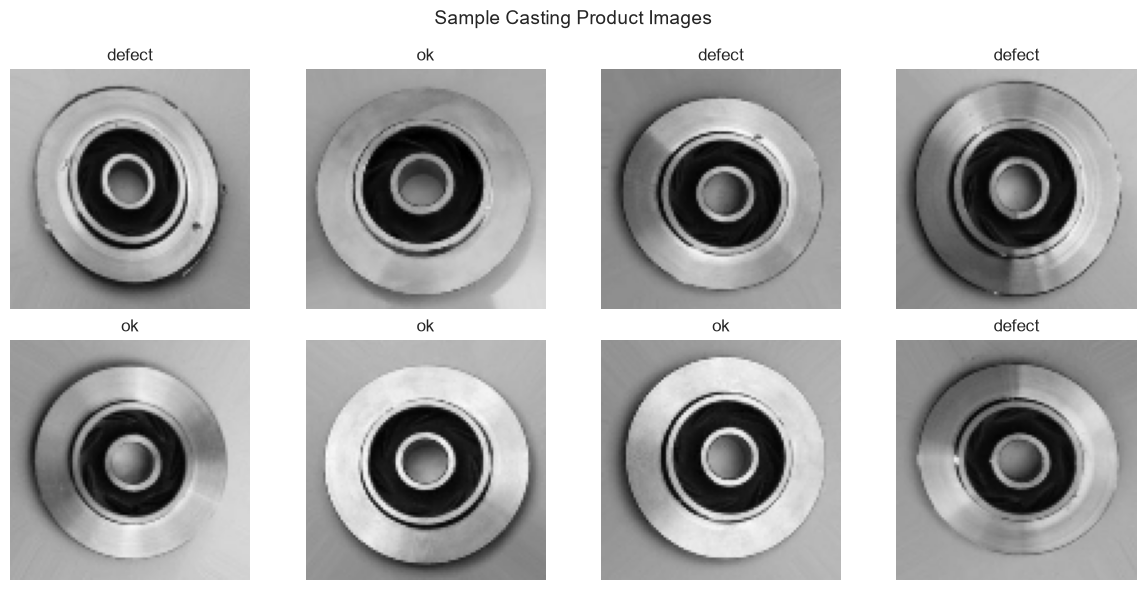

In [8]:
plt.figure(figsize=(12, 6))

for images, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label_index = int(labels[i].numpy()[0])
        plt.title(class_names[label_index])

        plt.axis("off")

plt.suptitle("Sample Casting Product Images", fontsize=14)
plt.tight_layout()
plt.show()

In [9]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel value range:",
          tf.reduce_min(images).numpy(),
          tf.reduce_max(images).numpy())

Image batch shape: (32, 96, 96, 3)
Label batch shape: (32, 1)
Pixel value range: 0.125 254.48828


In [ ]:
# preprocessing layers
rescale = tf.keras.layers.Rescaling(1.0 / 255)

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
])

AUTOTUNE = tf.data.AUTOTUNE

train_norm = train_ds.map(
    lambda x, y: (augment(rescale(x), training=True), y)
).prefetch(AUTOTUNE)

val_norm = val_ds.map(
    lambda x, y: (rescale(x), y)
).prefetch(AUTOTUNE)

test_norm = test_ds.map(
    lambda x, y: (rescale(x), y)
).prefetch(AUTOTUNE)

print("Preprocessing completed!")

Preprocessing completed!


In [11]:
for images, labels in train_norm.take(1):
    print("Image shape:", images.shape)
    print("Minimum pixel:", tf.reduce_min(images).numpy())
    print("Maximum pixel:", tf.reduce_max(images).numpy())

Image shape: (32, 96, 96, 3)
Minimum pixel: 0.006836651
Maximum pixel: 0.988325


In [12]:
# CNN model 
scratch = tf.keras.Sequential([
    tf.keras.layers.Input((IMG_SIZE, IMG_SIZE, 3)),

    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPool2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPool2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPool2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.4),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid"),
], name="scratch_cnn")

scratch.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

scratch.summary()

Model: "scratch_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 94, 94, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 47, 47, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 45, 45, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 22, 22, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 20, 20, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 10, 10, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       409,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 466,049 (1.78 MB)

 Trainable params: 466,049 (1.78 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# training the model
import time

t0 = time.time()

history = scratch.fit(
    train_norm,
    validation_data=val_norm,
    epochs=15,
    verbose=1
)

scratch_train_time = time.time() - t0

print(f"Trained in {scratch_train_time:.1f} seconds")

Epoch 1/15
166/166 ━━━━━━━━━━━━━━━━━━━━ 33s 186ms/step - accuracy: 0.6530 - loss: 0.6041 - val_accuracy: 0.8410 - val_loss: 0.4047
Epoch 2/15
166/166 ━━━━━━━━━━━━━━━━━━━━ 24s 145ms/step - accuracy: 0.8015 - loss: 0.4118 - val_accuracy: 0.9050 - val_loss: 0.2677
Epoch 3/15
166/166 ━━━━━━━━━━━━━━━━━━━━ 37s 119ms/step - accuracy: 0.8562 - loss: 0.3149 - val_accuracy: 0.8960 - val_loss: 0.2340
Epoch 4/15
166/166 ━━━━━━━━━━━━━━━━━━━━ 22s 130ms/step - accuracy: 0.9046 - loss: 0.2273 - val_accuracy: 0.9344 - val_loss: 0.1503
Epoch 5/15
166/166 ━━━━━━━━━━━━━━━━━━━━ 23s 137ms/step - accuracy: 0.9314 - loss: 0.1736 - val_accuracy: 0.9555 - val_loss: 0.1023
Epoch 6/15
166/166 ━━━━━━━━━━━━━━━━━━━━ 20s 117ms/step - accuracy: 0.9506 - loss: 0.1308 - val_accuracy: 0.9465 - val_loss: 0.1268
Epoch 7/15
166/166 ━━━━━━━━━━━━━━━━━━━━ 20s 118ms/step - accuracy: 0.9704 - loss: 0.0900 - val_accuracy: 0.9586 - val_loss: 0.1068
Epoch 8/15
166/166 ━━━━━━━━━━━━━━━━━━━━ 19s 114ms/step - accuracy: 0.9729 - loss: 0

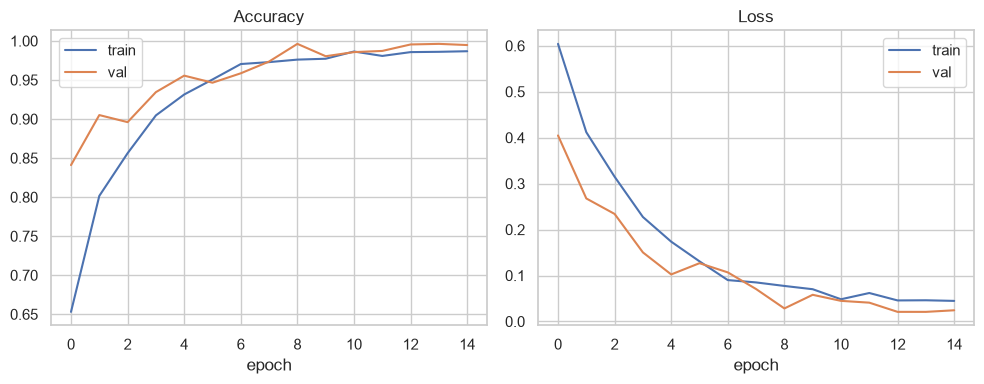

In [14]:
# plot accuracy and loss curves


fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(
    history.history["accuracy"],
    label="train"
)

axes[0].plot(
    history.history["val_accuracy"],
    label="val"
)

axes[0].set(
    title="Accuracy",
    xlabel="epoch"
)
axes[0].legend()

axes[1].plot(
    history.history["loss"],
    label="train"
)

axes[1].plot(
    history.history["val_loss"],
    label="val"
)

axes[1].set(
    title="Loss",
    xlabel="epoch"
)
axes[1].legend()

plt.tight_layout()
plt.show()

In [15]:
from pathlib import Path

Path("models").mkdir(exist_ok=True)

scratch.save("models/scratch_cnn.keras")

print("Scratch CNN saved successfully!")

Scratch CNN saved successfully!


In [ ]:
# Evaluvate function 

from sklearn.metrics import classification_report
import numpy as np

def evaluate(predict_fn, ds, name):
    y_true, y_prob = [], []

    for xb, yb in ds:
        y_prob.append(predict_fn(xb).ravel())
        y_true.append(yb.numpy().ravel())

    y_true = np.concatenate(y_true).astype(int)
    y_pred = (
        np.concatenate(y_prob) >= 0.5
    ).astype(int)

    acc = (y_pred == y_true).mean()

    print(f"{name}: test accuracy = {acc:.3f}")

    return y_true, y_pred, acc

In [17]:
# Evaluvation
scratch_true, scratch_pred, scratch_acc = evaluate(
    lambda xb: scratch.predict(xb, verbose=0),
    test_norm,
    "Scratch CNN"
)

print(
    classification_report(
        scratch_true,
        scratch_pred,
        target_names=class_names
    )
)

Scratch CNN: test accuracy = 0.989
              precision    recall  f1-score   support

      defect       1.00      0.98      0.99       453
          ok       0.97      1.00      0.98       262

    accuracy                           0.99       715
   macro avg       0.99      0.99      0.99       715
weighted avg       0.99      0.99      0.99       715



In [18]:
# Measure inference latency
def measure_latency(predict_fn, n=200):
    sample = next(iter(test_ds))[0][:1]

    predict_fn(sample)  # warmup

    t0 = time.perf_counter()

    for _ in range(n):
        predict_fn(sample)

    return (time.perf_counter() - t0) / n * 1000


scratch_latency = measure_latency(
    lambda xb: scratch.predict(
        rescale(xb),
        verbose=0
    )
)

print(
    f"Latency: {scratch_latency:.1f} ms/image"
)

Latency: 118.7 ms/image


In [ ]:
# Load MobileNetV2
base = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet",
    pooling="avg"
)

base.trainable = False

mobilenet_pre = (
    tf.keras.applications.mobilenet_v2.preprocess_input
)

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
MobileNetV2 loaded successfully!


In [20]:
# Extract features

def extract_features(ds):
    X, Y = [], []

    for xb, yb in ds:
        features = base(
            mobilenet_pre(xb),
            training=False
        ).numpy()

        X.append(features)
        Y.append(yb.numpy())

    return (
        np.concatenate(X),
        np.concatenate(Y).ravel()
    )


t0 = time.time()

Xtr, ytr = extract_features(train_ds)
Xva, yva = extract_features(val_ds)
Xte, yte = extract_features(test_ds)

feature_time = time.time() - t0

print("Training features:", Xtr.shape)
print("Validation features:", Xva.shape)
print("Testing features:", Xte.shape)
print(f"Feature extraction time: {feature_time:.1f}s")

Training features: (5306, 1280)
Validation features: (1327, 1280)
Testing features: (715, 1280)
Feature extraction time: 104.3s


In [21]:
# Train the classification head
head = tf.keras.Sequential([
    tf.keras.layers.Input((Xtr.shape[1],)),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

head.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

t0 = time.time()

head_history = head.fit(
    Xtr,
    ytr,
    validation_data=(Xva, yva),
    epochs=20,
    verbose=1
)

transfer_train_time = feature_time + (
    time.time() - t0
)

print(
    f"Total transfer learning time: "
    f"{transfer_train_time:.1f}s"
)

Epoch 1/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7678 - loss: 0.4681 - val_accuracy: 0.9307 - val_loss: 0.2591
Epoch 2/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9054 - loss: 0.2554 - val_accuracy: 0.9488 - val_loss: 0.1918
Epoch 3/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9246 - loss: 0.2048 - val_accuracy: 0.9593 - val_loss: 0.1625
Epoch 4/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9359 - loss: 0.1807 - val_accuracy: 0.9608 - val_loss: 0.1441
Epoch 5/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.9459 - loss: 0.1617 - val_accuracy: 0.9631 - val_loss: 0.1306
Epoch 6/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9461 - loss: 0.1539 - val_accuracy: 0.9661 - val_loss: 0.1219
Epoch 7/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9518 - loss: 0.1411 - val_accuracy: 0.9668 - val_loss: 0.1129
Epoch 8/20
166/166 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9583 - loss: 0.1252 - val_accuracy: 0.

In [22]:
# Evaluate MobileNetV2

transfer_pred = (
    head.predict(Xte, verbose=0).ravel() >= 0.5
).astype(int)

transfer_true = yte.astype(int)

transfer_acc = (
    transfer_pred == transfer_true
).mean()

print(f"Transfer accuracy: {transfer_acc:.3f}")

print(
    classification_report(
        transfer_true,
        transfer_pred,
        target_names=class_names
    )
)

Transfer accuracy: 0.979
              precision    recall  f1-score   support

      defect       0.99      0.98      0.98       453
          ok       0.97      0.98      0.97       262

    accuracy                           0.98       715
   macro avg       0.98      0.98      0.98       715
weighted avg       0.98      0.98      0.98       715



In [23]:
base.save("models/mobilenetv2_feature_extractor.keras")
head.save("models/mobilenetv2_classifier.keras")

print("Transfer-learning models saved!")

Transfer-learning models saved!


In [24]:
from sklearn.linear_model import LogisticRegression
import numpy as np
import time

def flatten_pixels(ds):
    X, Y = [], []

    for xb, yb in ds:
        X.append(
            (xb.numpy() / 255.0).reshape(len(xb), -1)
        )
        Y.append(yb.numpy())

    return (
        np.concatenate(X),
        np.concatenate(Y).ravel()
    )

Xtr_px, ytr_px = flatten_pixels(train_ds)
Xte_px, yte_px = flatten_pixels(test_ds)

print("Training shape:", Xtr_px.shape)
print("Testing shape:", Xte_px.shape)

Training shape: (5306, 27648)
Testing shape: (715, 27648)


In [ ]:
# Train Logistic Regression
t0 = time.time()

classical_model = LogisticRegression(max_iter=300)
classical_model.fit(Xtr_px, ytr_px)

classical_train_time = time.time() - t0

classical_acc = classical_model.score(
    Xte_px, yte_px
)

print(f"Classical accuracy: {classical_acc:.3f}")
print(f"Training time: {classical_train_time:.1f} seconds")

Classical accuracy: 0.890
Training time: 23.5 seconds


In [26]:
# Measure classical model inference latency

def measure_classical_latency(model, sample, n=200):
    model.predict(sample)  # warmup

    t0 = time.perf_counter()

    for _ in range(n):
        model.predict(sample)

    return (time.perf_counter() - t0) / n * 1000


classical_latency = measure_classical_latency(
    classical_model,
    Xte_px[:1]
)

print(f"Classical latency: {classical_latency:.3f} ms/image")

Classical latency: 0.233 ms/image


In [27]:
# Measure MobileNetV2 latency
def transfer_predict(xb):
    features = base(
        mobilenet_pre(xb),
        training=False
    )

    return head(features, training=False).numpy()


transfer_latency = measure_latency(
    transfer_predict
)

print(f"MobileNetV2 latency: {transfer_latency:.1f} ms/image")

MobileNetV2 latency: 208.9 ms/image


In [28]:
# comparison table

import pandas as pd

summary = pd.DataFrame([
    {
        "Model": "Classical (pixels)",
        "Test accuracy": classical_acc,
        "Train time (s)": classical_train_time,
        "Latency (ms/img)": classical_latency
    },
    {
        "Model": "CNN from scratch",
        "Test accuracy": scratch_acc,
        "Train time (s)": scratch_train_time,
        "Latency (ms/img)": scratch_latency
    },
    {
        "Model": "Transfer (MobileNetV2)",
        "Test accuracy": transfer_acc,
        "Train time (s)": transfer_train_time,
        "Latency (ms/img)": transfer_latency
    }
]).set_index("Model").round(3)

display(summary)

,Test accuracy,Train time (s),Latency (ms/img)
Model,,,
Classical (pixels),0.890,23.513,0.233
CNN from scratch,0.989,342.328,118.683
Transfer (MobileNetV2),0.979,119.227,208.910


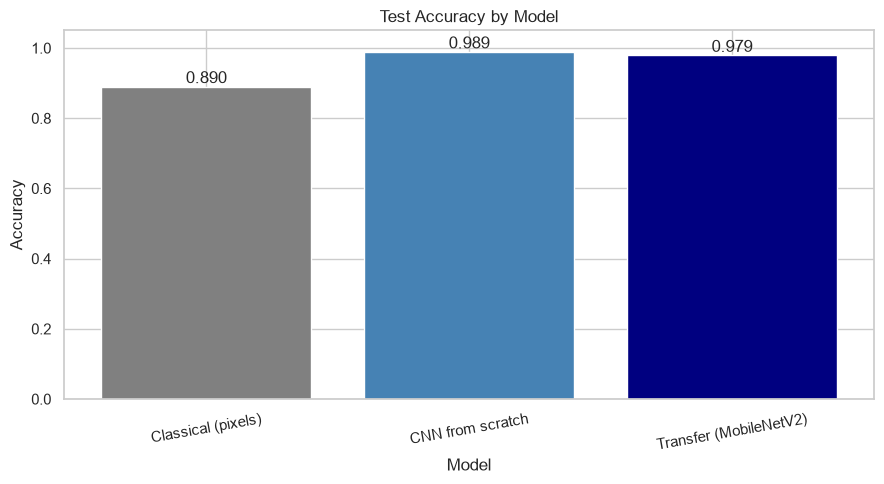

In [29]:
# Plot model accuracy comparison

plt.figure(figsize=(9, 5))

bars = plt.bar(
    summary.index,
    summary["Test accuracy"],
    color=["gray", "steelblue", "navy"]
)

plt.title("Test Accuracy by Model")
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.01,
        f"{height:.3f}",
        ha="center"
    )

plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

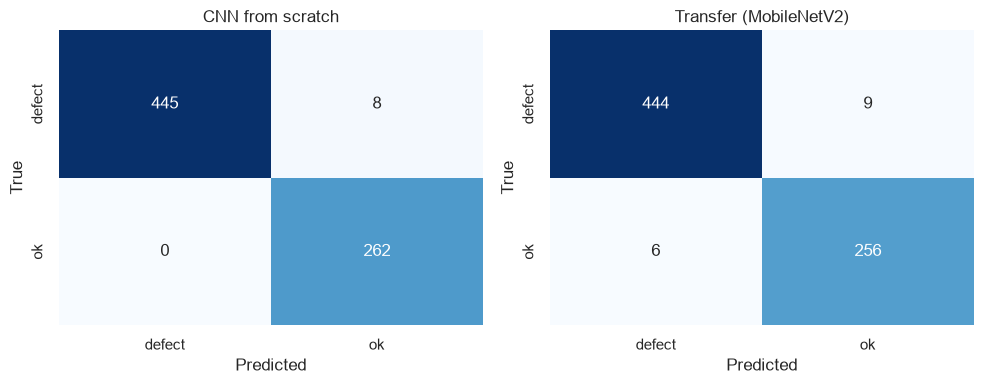

In [30]:
# confusion matrices
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (true, pred, name) in zip(
    axes,
    [
        (scratch_true, scratch_pred, "CNN from scratch"),
        (transfer_true, transfer_pred, "Transfer (MobileNetV2)")
    ]
):
    cm = confusion_matrix(
        true,
        pred,
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=class_names,
        yticklabels=class_names,
        ax=ax
    )

    ax.set(
        title=name,
        xlabel="Predicted",
        ylabel="True"
    )

plt.tight_layout()
plt.show()